## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [1]:
# Your Phase 1 solution to the problem goes here.
#Q1.1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

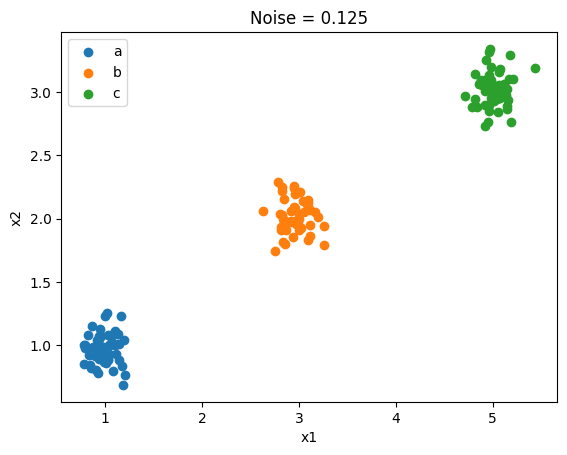

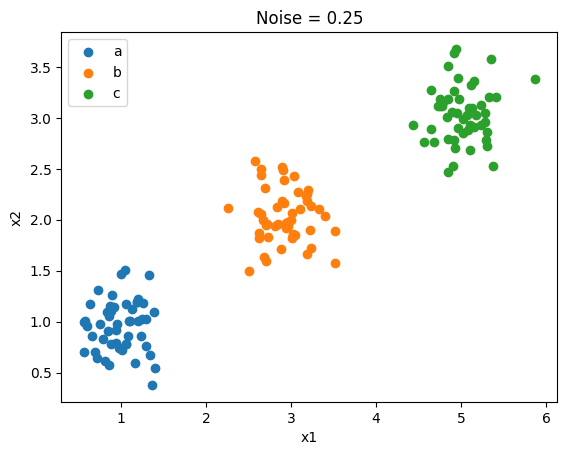

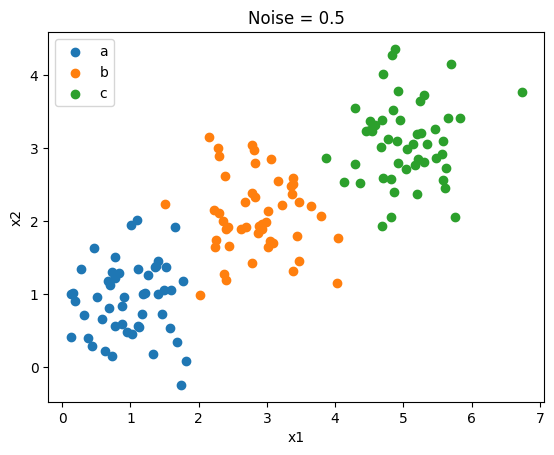

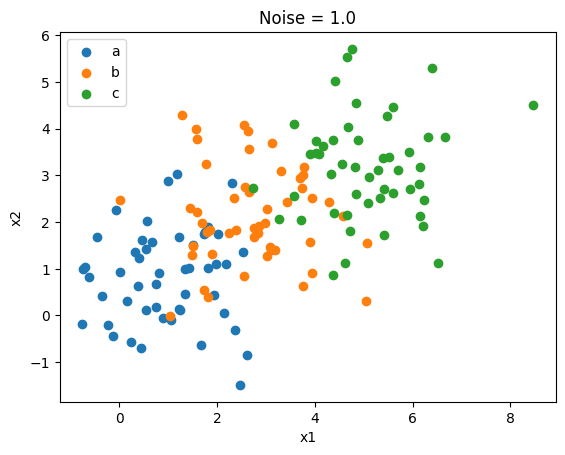

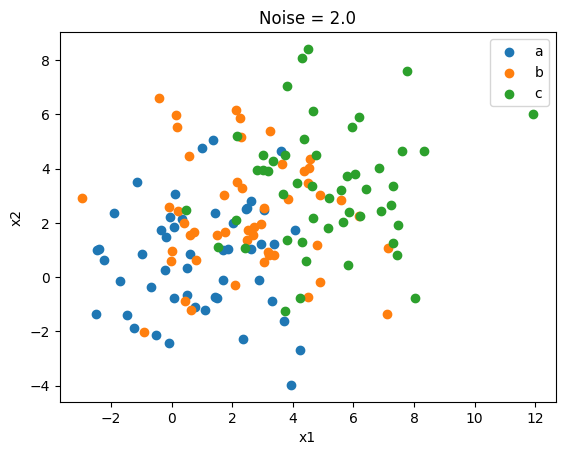

In [2]:
#Q1.2
import matplotlib.pyplot as plt
dfs = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]
for df, noise in zip(dfs, noises):
    for group in ['a', 'b', 'c']:
        data = df[df['group'] == group]
        plt.scatter(data['x1'], data['x2'], label=group)
    plt.title('Noise = ' + str(noise))
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend()
    plt.show()

The clusters are becoming less and less distinct as noise increases from 0.125 to 2.0. When noise is low, three groups are clearly separated. When noise = 0.5, the points become more spread out, but people can still identify their groups. WHen noise = 1.0 and 2.0, the groups start to overlap. It is hard to distinguish three groups.

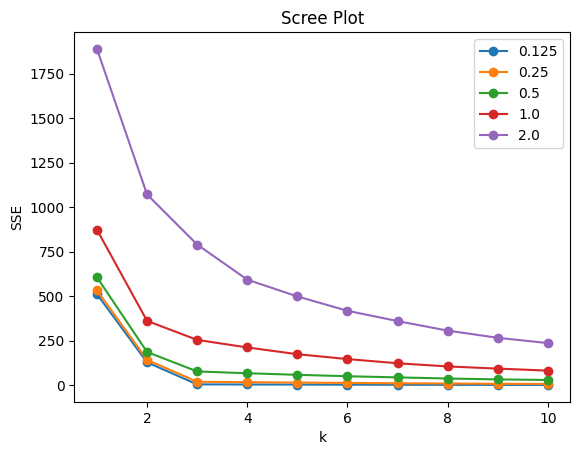

In [3]:
#Q1.3
from sklearn.cluster import KMeans
for df, noise in zip(dfs, noises):
    X = df[['x1', 'x2']]
    sse = []
    for k in range(1, 11):
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X)
        sse.append(model.inertia_)
    plt.plot(range(1, 11), sse, marker='o', label=str(noise))
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree Plot')
plt.legend()
plt.show()

The elbow in the scree plot becomes less clear as noise increases. When noise is low, at 0.125 and 0.25, there is a clear elbow at k=3, and the SSE decreases very slowly after that. At noise = 0.5, the elbow is still visible. As noise increases to 1.0 and 2.0, the elbow becomes harder to identify, and SSE becomes larger. As a result, it is more difficult to choose the best k when noise is high.

Q1.4
The elbow happens because SSE decreases quickly as k increases at first. In this simulation, there are three groups, so k=3 works well. After k=3, increasing k only reduces a little SSE. That is why the elbow is at k=3. When noise increases, the elbow becomes less clear.

In [5]:
#Q2.1
import pandas as pd
df = pd.read_csv('/SIPRI Military Expenditure Database.csv')
print(df.columns)
df.head()

Index(['index', 'Year', 'Country', 'Spending (2020 USD)', 'Percent of GDP',
       'Percent of Government Spending', 'Spending per Capita'],
      dtype='object')


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,0,1988,Afghanistan,NaN,NaN,NaN,NaN
1,1,1989,Afghanistan,NaN,NaN,NaN,NaN
2,2,1990,Afghanistan,NaN,NaN,NaN,NaN
3,3,1991,Afghanistan,NaN,NaN,NaN,NaN
4,4,1992,Afghanistan,NaN,NaN,NaN,NaN


In [8]:
df = df[df['Year'] == 2020]
df = df.dropna()
print(df.shape)
df.head()

(148, 7)


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


In [11]:
df.dtypes

,0
index,int64
Year,int64
Country,object
Spending (2020 USD),float64
Percent of GDP,float64
Percent of Government Spending,float64
Spending per Capita,float64


After selecting the year 2020 and dropping missing values, 148 countries remain. All four spending variables are numeric, so no further cleaning needed.

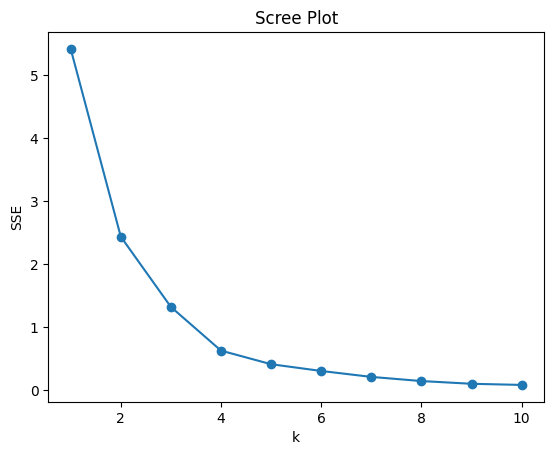

In [12]:
#Q2.2
columns = ['Spending (2020 USD)', 'Spending per Capita']
X = df[columns]
X = (X -X.min()) / (X.max() -X.min())
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
sse =[]
for k in range(1,11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    sse.append(model.inertia_)
plt.plot(range(1,11), sse, marker='o')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree Plot')
plt.show()

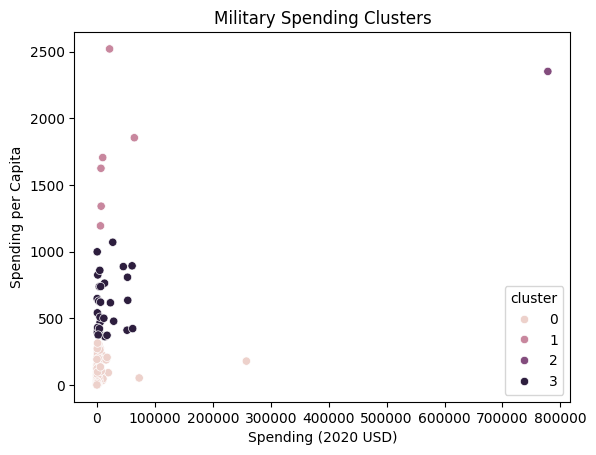

In [13]:
model = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] =model.fit_predict(X)
import seaborn as sns
sns.scatterplot(data=df, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster')
plt.title('Military Spending Clusters')
plt.show()

In [14]:
df.groupby('cluster')[columns].describe()

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                     111.0    4859.185065  25405.739131       8.622460   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                       1.0  778397.200000           NaN  778397.200000   
3                      30.0   17077.591354  20583.053357     405.790494   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0           130.010211     382.464677    2297.032353  257973.429834   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2        778397.200000  778397.200000  778397.200000  778397.200000   
3          2294.039665    5857.060906   26296.001003   61712.537169   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                     111.0    80.061470   83.501824     0.580129   
1                       6.0  1706.721916  466.375705  1193.598730   
2                       1.0  2351.631858         NaN  2351.631858   
3                      30.0   607.478618  206.928757   362.467076   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0          14.880549    47.056944   125.387558   314.201312  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2        2351.631858  2351.631858  2351.631858  2351.631858  
3         422.208252   579.004604   757.328513  1070.623322

In [19]:
df[df['Country'] == 'United States of America'][['Country', 'cluster']]

,Country,cluster
5540,United States of America,2


The scree plot suggest k = 4. Most countries are in Cluster 0. They have relatively low military spending and spending per capita. Cluster 1 has a high spending per capita. Cluster 3 has moderate spending per capita. The United States is the only country in Cluster 2. Its total military spending is much higher than other countries.

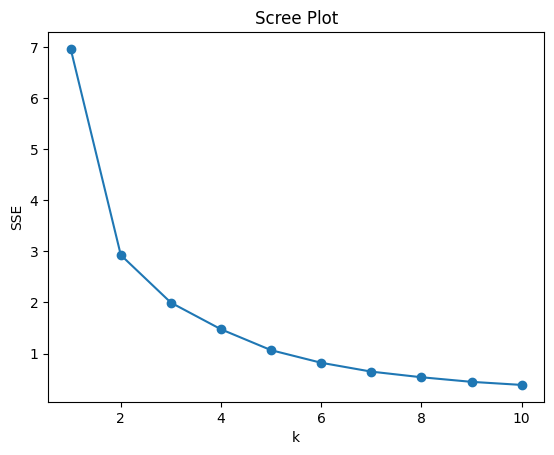

In [20]:
#Q2.3
columns2 = ['Percent of Government Spending', 'Percent of GDP']
X2 = df[columns2]
X2 = (X2 -X2.min()) / (X2.max() -X2.min())
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
sse2 =[]
for k in range(1,11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X2)
    sse2.append(model.inertia_)
plt.plot(range(1,11), sse2, marker='o')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree Plot')
plt.show()

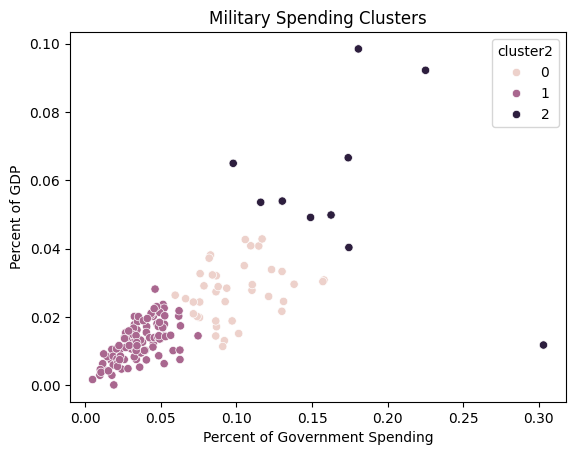

In [21]:
model2 = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster2'] =model2.fit_predict(X2)
import seaborn as sns
sns.scatterplot(data=df, x='Percent of Government Spending', y='Percent of GDP', hue='cluster2')
plt.title('Military Spending Clusters')
plt.show()

In [22]:
df.groupby('cluster2')[columns2].describe()

Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  99.0  0.035777  0.014549  0.004896   
2                                  10.0  0.171289  0.058725  0.097882   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                      
               std       min       25%       50%       75%       max  
cluster2                                                              
0         0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1         0.005681  0.000054  0.008393  0.013191  0.016752  0.028132  
2         0.024867  0.011742  0.049297  0.053729  0.066190  0.098470

In [23]:
df[df['Country'] == 'United States of America'][['Country', 'cluster2']]

,Country,cluster2
5540,United States of America,0


The scree plot suggests k = 3. Most countries are in Cluster 1. They have relatively low military spending percentages. Cluster 0 has moderate percentages. Cluster 2 has high percentages. The United States is in Cluster 0. In Q2.2, the United States was the only country in Cluster 2 because of its high total spending. However, its military spending percentages are not the highest.

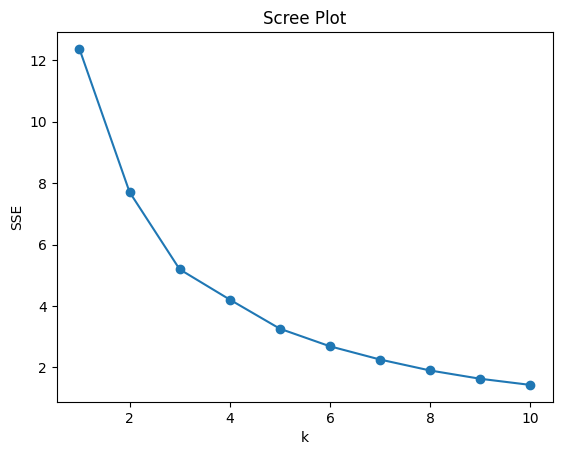

In [25]:
#Q2.4
columns3 = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
X3 = df[columns3]
X3 = (X3 -X3.min()) / (X3.max() -X3.min())
sse3 =[]
for k in range(1,11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X3)
    sse3.append(model.inertia_)
plt.plot(range(1,11), sse3, marker='o')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree Plot')
plt.show()

In [26]:
model3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster3'] = model3.fit_predict(X3)
df.groupby('cluster3')[columns3].describe()

Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster3                                                                  
0                       31.0    8786.086602   17901.909108   162.373364   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                      111.0    7086.472777   26479.379918     8.622460   

                                                                  \
                  25%           50%           75%            max   
cluster3                                                           
0          467.787851   1404.787234   7739.166193   72937.064048   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          130.010211    567.650747   3910.107493  257973.429834   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster3                                   ...                                  
0                       31.0   212.689100  ...                       0.134663   
1                        6.0  1875.150751  ...                       0.164503   
2                      111.0   196.926833  ...                       0.050505   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster3                                                                    
0         0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
1         0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2         0.092044          111.0  0.013419  0.005996  0.000054  0.008873   

                                        
               50%       75%       max  
cluster3                                
0         0.032024  0.040531  0.066600  
1         0.059257  0.085398  0.098470  
2         0.013589  0.017769  0.028132  

[3 rows x 32 columns]

In [27]:
df.groupby('cluster3')[columns3].mean()

,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
cluster3,,,,
0,8786.086602,212.689100,0.122985,0.033492
1,147964.582042,1875.150751,0.135351,0.062634
2,7086.472777,196.926833,0.040350,0.013419


In [28]:
df[df['Country'] == 'United States of America'][['Country', 'cluster3']]

,Country,cluster3
5540,United States of America,1


The scree plot suggests k = 3. Most countries are in Cluster 2. They have relatively low military spending and spending percentages. Cluster 0 has higher spending percentages than Cluster 2. Cluster 1 has the highest average spending and spending percentages, and the United States is in Cluster 1 with five other countries. Compared to Q2.2 and Q2.3, Q2.4 considers both the amount of military spending and spending percentages, so the clustering results changed.

2.5
The k-MC algorithm found some useful patterns.It helps group countries with similar spending levels and makes it easier to compare between them. Most countries have relatively low military spending, while a small number of countries spend much more. As for United States, In Q2.2, the it was alone in the cluster because of high total spending. In Q2.3, it is grouped with other countries when we used spending percentages. In Q2.4, it was grouped with five other countries when all four variables were used. This indicates countries can have differences and similarities depending on measures.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]